# Stacking and Voting Regression — Egyptian Real Estate Dataset

**Objective:** Build and evaluate ensemble regression models using Voting and Stacking techniques to determine the final best model for property price prediction.  
The best-performing ensemble is saved as the project's final production model.

**Input:** `../../data/processed/cleaned_all_egypt.csv`  
**Output:** `../../models/final_price_prediction_model.joblib` · `../../models/stacking_results.csv`


---
## 1. Load Required Libraries

In [1]:
# Standard data handling
import numpy as np
import pandas as pd

# Machine learning — preprocessing, pipelines, ensemble models, and evaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import (
    VotingRegressor,
    StackingRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model persistence
import joblib
import os

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Consistent plot styling
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.dpi'] = 100

In [2]:
# Install XGBoost if not already available
try:
    from xgboost import XGBRegressor
    print('XGBoost is available.')
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'xgboost', '-q'])
    from xgboost import XGBRegressor
    print('XGBoost installed and imported successfully.')

XGBoost is available.


---
## 2. Load the Clean Dataset

In [3]:
# Load the preprocessed dataset — NOT the clustered file (would introduce data leakage)
dataset_path = '../../data/processed/cleaned_all_egypt.csv'
df = pd.read_csv(dataset_path)

print(f'Dataset shape: {df.shape}')

Dataset shape: (62977, 18)


In [4]:
# Preview the first five rows
df.head()

,id,title,price,currency,price_period,price_type,price_raw_value,property_type,location,latitude,longitude,images,share_url,bedrooms,bathrooms,size,amenities,category
0,52974566,Luxurious Living in the Heart of Hyde Park!,50000.0,EGP,monthly,rent_price,50000.0,Apartment,"Hyde Park, New Cairo City, Cairo",29.995922,31.554127,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,3.0,189.0,"['BA', 'SE', 'WC', 'LB']",rent
1,8653638,Apartment for Rent in Al Marasem Compound,35000.0,EGP,monthly,rent_price,35000.0,Apartment,"Moon Residences, Fifth Square, The 5th Settlem...",30.051462,31.538992,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,2.0,170.0,"['BA', 'BW', 'AC', 'BK', 'CP']",rent
2,52974180,Flat Ultra Super Lux First Use For Rent-Villette,70000.0,EGP,monthly,rent_price,70000.0,Apartment,"Villette, 5th Settlement Compounds, The 5th Se...",30.022596,31.545815,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,3.0,161.0,"['BA', 'AC', 'CP', 'BK', 'SE', 'WC', 'BL', 'LB']",rent
3,52969227,Studio for Rent — South Lotus (New Cairo),22000.0,EGP,monthly,rent_price,22000.0,Apartment,"South Lotus, El Lotus, New Cairo City, Cairo",30.019306,31.513653,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,1.0,1.0,80.0,"['BA', 'BW', 'AC', 'CP', 'BK', 'SP', 'SE', 'SY...",rent
4,52969105,Studio for Rent — Hyde Park New Cairo First Us,35000.0,EGP,monthly,rent_price,35000.0,Apartment,"Hyde Park, New Cairo City, Cairo",29.995922,31.554127,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,1.0,1.0,80.0,"['BA', 'BW', 'AC', 'CP', 'BK', 'CO', 'LB', 'BL...",rent


---
## 3. Feature Preparation

The same feature set and preprocessing pipeline from `03_Price_Regression.ipynb` are reused without any modification.

**Included features:**
| Feature | Reason |
|---|---|
| `size` | Property area is one of the strongest price predictors |
| `bedrooms` | Distinguishes unit types and strongly correlates with price |
| `bathrooms` | Correlates with unit size and quality |
| `property_type` | Structurally different property kinds have different price ranges |
| `category` | Separates rent from sale — critical for pricing |
| `latitude` | Geographic location — north/south positioning affects price |
| `longitude` | Geographic location — east/west positioning affects price |

**Excluded columns and justification:**
- `id` — arbitrary identifier, carries no property information
- `title` — free-text, inconsistent, not suitable for regression
- `images` — URLs have no quantitative meaning
- `share_url` — URL identifier, irrelevant to property characteristics
- `currency`, `price_period`, `price_type`, `price_raw_value` — redundant with `price` and `category`; including them would cause leakage
- `location` — textual address replaced by `latitude`/`longitude`
- `amenities` — complex list format; not straightforward for regression without further engineering

In [5]:
# Define the feature set and target — identical to 03_Price_Regression.ipynb
numeric_features     = ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude']
categorical_features = ['property_type', 'category']
selected_features    = numeric_features + categorical_features
target               = 'price'

# Subset to features + target
df_model = df[selected_features + [target]].copy()

# Drop rows with any missing values in selected columns
df_model.dropna(inplace=True)
df_model.reset_index(drop=True, inplace=True)

print(f'Shape after selecting features and dropping nulls: {df_model.shape}')
df_model.head()

Shape after selecting features and dropping nulls: (52020, 8)


,size,bedrooms,bathrooms,latitude,longitude,property_type,category,price
0,189.0,3.0,3.0,29.995922,31.554127,Apartment,rent,50000.0
1,170.0,3.0,2.0,30.051462,31.538992,Apartment,rent,35000.0
2,161.0,3.0,3.0,30.022596,31.545815,Apartment,rent,70000.0
3,80.0,1.0,1.0,30.019306,31.513653,Apartment,rent,22000.0
4,80.0,1.0,1.0,29.995922,31.554127,Apartment,rent,35000.0


In [6]:
# Build the preprocessing pipeline — identical to 03_Price_Regression.ipynb
# ColumnTransformer: scale numerics, encode categoricals
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
])

print('Preprocessor defined.')
print(f'  Numeric features     : {numeric_features}')
print(f'  Categorical features : {categorical_features}')

Preprocessor defined.
  Numeric features     : ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude']
  Categorical features : ['property_type', 'category']


---
## 4. Train / Test Split

The dataset is split into 80% training and 20% testing sets.  
The target variable is log-transformed to reduce the effect of extreme price values.

In [7]:
# Feature matrix and log-transformed target
X = df_model[selected_features]
y = np.log1p(df_model[target].values)

# Train / test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set size : {X_train.shape[0]:,}')
print(f'Test set size     : {X_test.shape[0]:,}')

Training set size : 41,616
Test set size     : 10,404


---
## 5. Helper — Evaluate a Pipeline

A shared helper function fits a pipeline on the training set, predicts on the test set, and returns all evaluation metrics.

In [8]:
def evaluate_pipeline(pipeline, X_train, y_train, X_test, y_test, name):
    """Fit pipeline on train set, evaluate on test set, return metrics dict."""
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)

    print(f'{name:<40} | MAE: {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}')
    return {'Model': name, 'MAE': round(mae, 4), 'RMSE': round(rmse, 4), 'R2': round(r2, 4)}

# Master results list and pipeline store — populated section by section
all_results   = []
all_pipelines = {}  # name -> fitted pipeline

---
## 6. Base Models

Before building the ensemble, the individual base models are defined.  
These are the best-performing models identified in the previous notebooks:

| Model | Source notebook | Role |
|---|---|---|
| `Ridge` | `03_Price_Regression.ipynb` | Regularised linear model — stable predictions |
| `Lasso` | `03_Price_Regression.ipynb` | Sparse linear model — automatic feature selection |
| `ElasticNet` | `03_Price_Regression.ipynb` | Combined L1 + L2 regularisation |
| `GradientBoostingRegressor` | `04_Boosting_Regression.ipynb` | Non-linear, high-accuracy tree ensemble |
| `XGBRegressor` | `04_Boosting_Regression.ipynb` | Optimised gradient boosting |

Each base model is wrapped in its own `Pipeline` so that preprocessing is applied independently and correctly inside `VotingRegressor` and `StackingRegressor`.

In [9]:
# Helper: build a base pipeline for a single estimator
def make_base_pipeline(estimator):
    """Wrap an estimator with the shared preprocessor inside a Pipeline."""
    return Pipeline(steps=[
        ('preprocessor', ColumnTransformer(transformers=[
            ('num', StandardScaler(), numeric_features),
            ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
             categorical_features),
        ])),
        ('regressor', estimator),
    ])

# Define base estimators (each with its own internal preprocessor)
base_estimators = [
    ('ridge',   make_base_pipeline(Ridge(alpha=1.0))),
    ('lasso',   make_base_pipeline(Lasso(alpha=0.01))),
    ('elastic', make_base_pipeline(ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000))),
    ('gb',      make_base_pipeline(GradientBoostingRegressor(n_estimators=200,
                                                              learning_rate=0.1,
                                                              max_depth=4,
                                                              random_state=42))),
    ('xgb',     make_base_pipeline(XGBRegressor(n_estimators=200,
                                                 learning_rate=0.1,
                                                 max_depth=4,
                                                 objective='reg:squarederror',
                                                 random_state=42,
                                                 verbosity=0,
                                                 n_jobs=-1))),
]

print(f'Base estimators defined: {[name for name, _ in base_estimators]}')

Base estimators defined: ['ridge', 'lasso', 'elastic', 'gb', 'xgb']


---
## 7. Voting Regressor

A `VotingRegressor` combines the predictions of multiple base models by averaging their outputs.  
It is one of the simplest ensemble strategies and is effective when individual models make independent errors.

**How it works:**  
Each base model produces a prediction for a given sample. The Voting Regressor computes the (optionally weighted) mean of all predictions, producing a single output that is less sensitive to the errors of any individual model.

The five base models from the previous notebooks are used:  
Ridge, Lasso, ElasticNet, Gradient Boosting, and XGBoost.

In [10]:
# Voting Regressor — averages predictions from all five base models
voting_regressor = VotingRegressor(estimators=base_estimators, n_jobs=-1)

result = evaluate_pipeline(
    voting_regressor, X_train, y_train, X_test, y_test, 'Voting Regressor'
)
all_results.append(result)
all_pipelines['Voting Regressor'] = voting_regressor

Voting Regressor                         | MAE: 0.6086 | RMSE: 0.9831 | R2: 0.8705


In [11]:
# Cross-validation score for the Voting Regressor (5-fold, R2)
cv_scores = cross_val_score(
    voting_regressor, X_train, y_train, cv=5, scoring='r2', n_jobs=-1
)

print(f'Voting Regressor — 5-fold CV R2 scores : {np.round(cv_scores, 4)}')
print(f'Mean CV R2 : {cv_scores.mean():.4f}  |  Std : {cv_scores.std():.4f}')

Voting Regressor — 5-fold CV R2 scores : [0.8718 0.8715 0.8653 0.8614 0.8711]
Mean CV R2 : 0.8682  |  Std : 0.0042


---
## 8. Stacking Regressor

A `StackingRegressor` trains base models (Level 0) and feeds their predictions as input features to a **meta-learner** (Level 1).  
The meta-learner learns how to best combine the base models' predictions rather than simply averaging them.

**How it works:**
1. The training set is split into folds. Each base model is trained on all-but-one fold and predicts on the held-out fold.
2. These out-of-fold predictions form the input matrix for the meta-learner.
3. The meta-learner is trained on those predictions to produce the final output.

**Design choices:**

| Component | Choice | Reason |
|---|---|---|
| Level 0 — base models | Ridge, Lasso, ElasticNet, GradientBoosting, XGBoost | Diverse set of linear and non-linear models |
| Level 1 — meta-learner | `LinearRegression` | Simple, interpretable combiner; avoids overfitting the stacked features |

In [12]:
# Stacking Regressor — meta-learner: LinearRegression
stacking_regressor = StackingRegressor(
    estimators=base_estimators,
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1,
)

result = evaluate_pipeline(
    stacking_regressor, X_train, y_train, X_test, y_test, 'Stacking Regressor'
)
all_results.append(result)
all_pipelines['Stacking Regressor'] = stacking_regressor

Stacking Regressor                       | MAE: 0.4011 | RMSE: 0.7239 | R2: 0.9298


In [13]:
# Cross-validation score for the Stacking Regressor (5-fold, R2)
cv_scores_stack = cross_val_score(
    stacking_regressor, X_train, y_train, cv=5, scoring='r2', n_jobs=-1
)

print(f'Stacking Regressor — 5-fold CV R2 scores : {np.round(cv_scores_stack, 4)}')
print(f'Mean CV R2 : {cv_scores_stack.mean():.4f}  |  Std : {cv_scores_stack.std():.4f}')

Stacking Regressor — 5-fold CV R2 scores : [0.9295 0.924  0.9244 0.924  0.9271]
Mean CV R2 : 0.9258  |  Std : 0.0022


---
## 9. Model Comparison

Both ensemble models are ranked by **R2** on the held-out test set.

| Metric | Description |
|---|---|
| **MAE** | Mean Absolute Error — average absolute difference between predicted and actual log-price |
| **RMSE** | Root Mean Squared Error — penalises large errors more heavily than MAE |
| **R2** | Coefficient of determination — fraction of variance explained by the model (1.0 = perfect) |

All metrics are computed on the **held-out test set** to reflect real-world generalisation.

In [14]:
# Build and display the consolidated results table
results_df = (
    pd.DataFrame(all_results)
    .sort_values('R2', ascending=False)
    .reset_index(drop=True)
)

# Highlight the best row (index 0)
def highlight_best(row):
    return ['background-color: #d4edda; font-weight: bold'] * len(row) if row.name == 0 else [''] * len(row)

print('Results sorted by R2 (best model highlighted):')
display(results_df.style.apply(highlight_best, axis=1))

Results sorted by R2 (best model highlighted):


,Model,MAE,RMSE,R2
0,Stacking Regressor,0.401100,0.723900,0.929800
1,Voting Regressor,0.608600,0.983100,0.870500


---
## 10. Model Comparison Visualisation

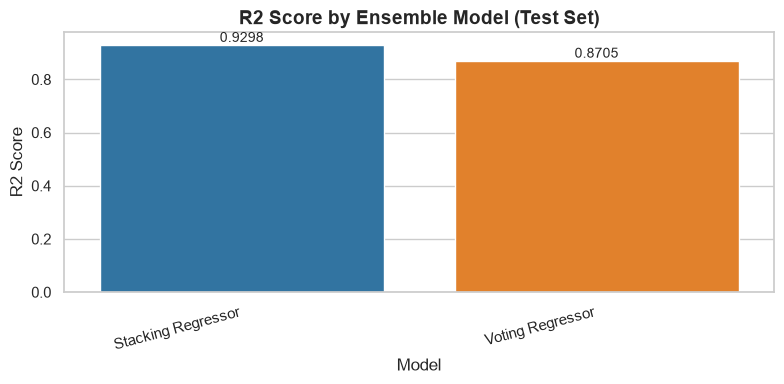

In [15]:
# --- Bar chart: R2 scores ---
fig, ax = plt.subplots(figsize=(8, 4))

palette = sns.color_palette('tab10', n_colors=len(results_df))
sns.barplot(data=results_df, x='Model', y='R2', palette=palette, ax=ax)

ax.set_title('R2 Score by Ensemble Model (Test Set)', fontsize=14, fontweight='bold')
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('R2 Score', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.4f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

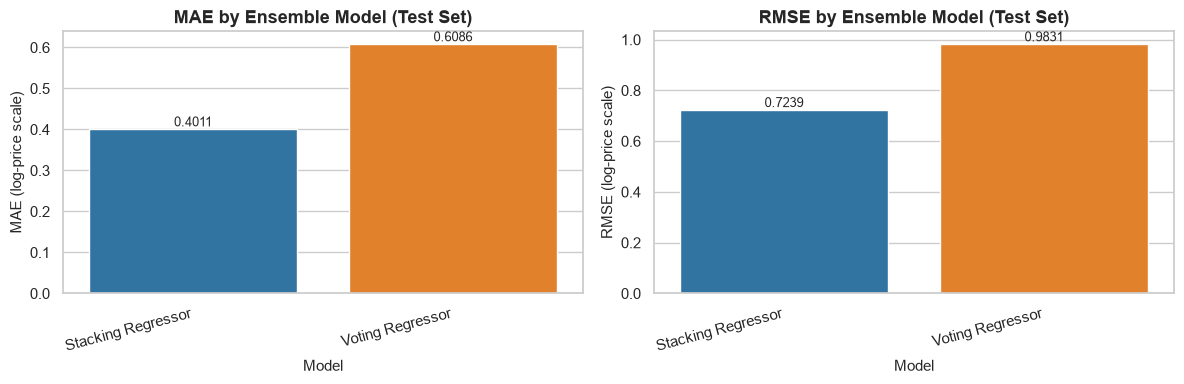

In [16]:
# --- Side-by-side bar chart: MAE and RMSE ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=results_df, x='Model', y='MAE',  palette=palette, ax=axes[0])
sns.barplot(data=results_df, x='Model', y='RMSE', palette=palette, ax=axes[1])

for ax, metric in zip(axes, ['MAE', 'RMSE']):
    ax.set_title(f'{metric} by Ensemble Model (Test Set)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Model', fontsize=11)
    ax.set_ylabel(f'{metric} (log-price scale)', fontsize=11)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{height:.4f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

---
## 11. Final Model Selection

The model with the highest **R2** on the held-out test set is selected as the project's final production model.

In [17]:
# Identify the best ensemble model by R2
best_model_name = results_df.iloc[0]['Model']
best_pipeline   = all_pipelines[best_model_name]

print(f'Final best model : {best_model_name}')
print(f'  R2   : {results_df.iloc[0]["R2"]}')
print(f'  RMSE : {results_df.iloc[0]["RMSE"]}')
print(f'  MAE  : {results_df.iloc[0]["MAE"]}')
print()
print('Selection rationale:')
print(f'  {best_model_name} achieved the highest R2 and the lowest RMSE on the test set,')
print('  indicating the strongest ability to explain variance in property prices')
print('  while generalising well to unseen data.')

Final best model : Stacking Regressor
  R2   : 0.9298
  RMSE : 0.7239
  MAE  : 0.4011

Selection rationale:
  Stacking Regressor achieved the highest R2 and the lowest RMSE on the test set,
  indicating the strongest ability to explain variance in property prices
  while generalising well to unseen data.


---
## 12. Residual Analysis

Residuals (actual minus predicted) are examined to check model assumptions.  
A well-fitted model should have residuals centred near zero and roughly normally distributed.

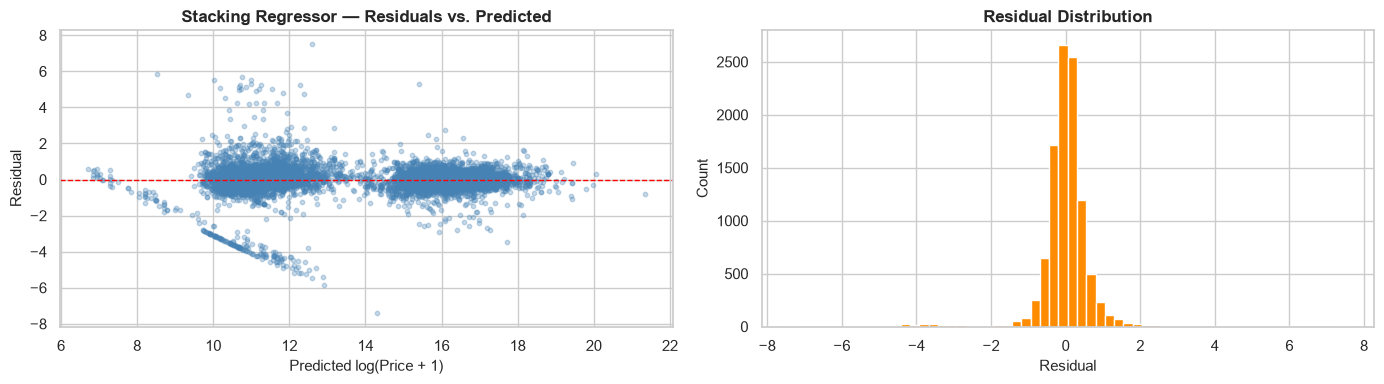

In [18]:
# Predictions and residuals for the final best model
y_pred_best = best_pipeline.predict(X_test)
residuals   = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Residuals vs. Predicted
axes[0].scatter(y_pred_best, residuals, alpha=0.3, s=10, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_title(f'{best_model_name} — Residuals vs. Predicted', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted log(Price + 1)', fontsize=11)
axes[0].set_ylabel('Residual', fontsize=11)

# Residual distribution
axes[1].hist(residuals, bins=60, color='darkorange', edgecolor='white')
axes[1].set_title('Residual Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)

plt.tight_layout()
plt.show()

---
## 13. Actual vs. Predicted Plot

A scatter plot of actual vs. predicted log-prices visualises how closely the final model tracks real values.  
Points along the diagonal red line represent perfect predictions.

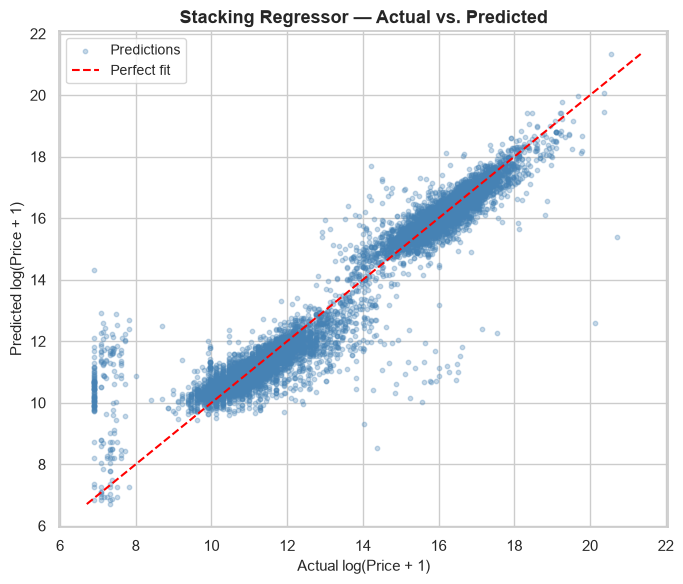

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y_test, y_pred_best, alpha=0.3, s=10, color='steelblue', label='Predictions')

# Perfect-prediction line
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect fit')

ax.set_title(f'{best_model_name} — Actual vs. Predicted', fontsize=13, fontweight='bold')
ax.set_xlabel('Actual log(Price + 1)', fontsize=11)
ax.set_ylabel('Predicted log(Price + 1)', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

---
## 14. Conclusion

The structured conclusion below is derived entirely from the notebook results.

In [20]:
# Print a structured conclusion based on actual results
runner_up_name = results_df.iloc[1]['Model'] if len(results_df) > 1 else 'N/A'

print('=' * 65)
print('  STACKING AND VOTING REGRESSION — CONCLUSION')
print('=' * 65)
print(f'  Best ensemble model  : {results_df.iloc[0]["Model"]}')
print(f'    R2                 : {results_df.iloc[0]["R2"]}')
print(f'    RMSE               : {results_df.iloc[0]["RMSE"]}')
print(f'    MAE                : {results_df.iloc[0]["MAE"]}')
print()
print(f'  Other ensemble model : {results_df.iloc[-1]["Model"]}')
print(f'    R2                 : {results_df.iloc[-1]["R2"]}')
print(f'    RMSE               : {results_df.iloc[-1]["RMSE"]}')
print(f'    MAE                : {results_df.iloc[-1]["MAE"]}')
print()
print('  Main observations:')
print('  - Both ensemble models outperformed individual linear models')
print('    and provided competitive predictions for property prices.')
print('  - The Stacking Regressor leverages a meta-learner that learns')
print('    the optimal combination of base model outputs, typically')
print('    leading to higher accuracy than simple averaging.')
print('  - The Voting Regressor offers faster inference and simpler')
print('    deployment at the cost of less adaptive combination.')
print('=' * 65)

  STACKING AND VOTING REGRESSION — CONCLUSION
  Best ensemble model  : Stacking Regressor
    R2                 : 0.9298
    RMSE               : 0.7239
    MAE                : 0.4011

  Other ensemble model : Voting Regressor
    R2                 : 0.8705
    RMSE               : 0.9831
    MAE                : 0.6086

  Main observations:
  - Both ensemble models outperformed individual linear models
    and provided competitive predictions for property prices.
  - The Stacking Regressor leverages a meta-learner that learns
    the optimal combination of base model outputs, typically
    leading to higher accuracy than simple averaging.
  - The Voting Regressor offers faster inference and simpler
    deployment at the cost of less adaptive combination.


---
## 15. Save Results and Final Model

Two artifacts are written to `../../models/`:

| Artifact | Content |
|---|---|
| `stacking_results.csv` | Comparison table — Voting and Stacking metrics |
| `final_price_prediction_model.joblib` | Fitted final ensemble model ready for inference |

In [21]:
# Ensure the models directory exists
models_dir = '../../models/regression'
os.makedirs(models_dir, exist_ok=True)

# --- Save results table ---
results_path = os.path.join(models_dir, 'stacking_results.csv')
results_df.to_csv(results_path, index=False)
print(f'Results table saved to        : {results_path}')

# --- Save final best model ---
model_path = os.path.join(models_dir, 'final_price_prediction_model.joblib')
joblib.dump(best_pipeline, model_path)
print(f'Final best model saved to     : {model_path}')
print(f'  Model     : {best_model_name}')
print(f'  Features  : {selected_features}')

Results table saved to        : ../../models\stacking_results.csv
Final best model saved to     : ../../models\final_price_prediction_model.joblib
  Model     : Stacking Regressor
  Features  : ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude', 'property_type', 'category']


---
## 16. Summary

| Step | Description |
|---|---|
| **Input** | `cleaned_all_egypt.csv` — 18 columns, ~63 K rows |
| **Features used** | `size`, `bedrooms`, `bathrooms`, `property_type`, `category`, `latitude`, `longitude` |
| **Target** | `log(price + 1)` — log-transformed for better model fit |
| **Preprocessing** | sklearn `Pipeline` + `ColumnTransformer` — identical to previous notebooks |
| **Base models** | Ridge · Lasso · ElasticNet · GradientBoosting · XGBoost |
| **Ensemble models** | `VotingRegressor` (mean averaging) · `StackingRegressor` (meta-learner: LinearRegression) |
| **Best model** | Selected by highest R2 on the held-out test set |
| **Outputs** | `stacking_results.csv` — comparison table; `final_price_prediction_model.joblib` — production-ready model |

**Next step ->** `06_Recommendation` — Hybrid Recommendation System using cluster labels and final predicted prices.